# TP2 — Smoking Prediction
## 01. Data Understanding & Data Quality

### Objetivo

El propósito de este proyecto es desarrollar un modelo de clasificación binaria capaz de predecir si una persona es fumadora (`smoking = 1`) o no fumadora (`smoking = 0`) a partir de características demográficas y clínicas.

El trabajo comprende la exploración y preparación de los datos, el entrenamiento y validación de modelos, y la generación de predicciones sobre un conjunto de datos sin etiquetar.

La métrica principal de evaluación será el **F1-score de la clase positiva (`smoking = 1`)**, de acuerdo con la consigna.

### Alcance de esta notebook

Esta primera etapa se centra en examinar la estructura, integridad y representación de los datos, identificar posibles problemas de calidad y explorar patrones relevantes para el posterior modelado.

Las transformaciones se documentarán y reutilizarán en el proceso de entrenamiento y predicción para garantizar la reproducibilidad.

In [19]:

from pathlib import Path
import pandas as pd

# Ubicación de los archivos originales
DATA_DIR = Path("../data/raw")

# Carga de los datasets
df_train = pd.read_excel(DATA_DIR / "smoking_prediction.xlsx")
df_predict = pd.read_excel(DATA_DIR / "smoking_prediction_entrega.xlsx")

# Dimensiones y estructura inicial
print("Dataset etiquetado:", df_train.shape)
print("Dataset sin etiquetar:", df_predict.shape)

print("\nColumnas del dataset etiquetado:")
print(df_train.columns.tolist())

print("\nPrimeras cinco observaciones:")
display(df_train.head())


Dataset etiquetado: (50000, 27)
Dataset sin etiquetar: (5692, 26)

Columnas del dataset etiquetado:
['ID', 'gender', 'age', 'height(cm)', 'weight(kg)', 'waist(cm)', 'eyesight(left)', 'eyesight(right)', 'hearing(left)', 'hearing(right)', 'systolic', 'relaxation', 'fasting blood sugar', 'Cholesterol', 'triglyceride', 'HDL', 'LDL', 'hemoglobin', 'Urine protein', 'serum creatinine', 'AST', 'ALT', 'Gtp', 'oral', 'dental caries', 'tartar', 'smoking']

Primeras cinco observaciones:


,ID,gender,age,height(cm),weight(kg),waist(cm),eyesight(left),eyesight(right),hearing(left),hearing(right),...,hemoglobin,Urine protein,serum creatinine,AST,ALT,Gtp,oral,dental caries,tartar,smoking
0,0,F,40,155,60,3.377083,0.043056,0.041667,0.041667,0.041667,...,0.506250,0.041667,0.004861,0.750000,0.791667,1.125000,Y,0,Y,0
1,1,F,40,160,60,3.375000,0.005556,0.004167,0.041667,0.041667,...,0.504861,0.041667,0.004167,0.916667,0.791667,0.750000,Y,0,Y,0
2,2,M,55,170,60,3.333333,0.005556,0.005556,0.041667,0.041667,...,0.630556,0.041667,0.041667,0.875000,0.666667,0.916667,Y,0,N,1
3,3,M,40,165,70,3.666667,0.045139,0.045139,0.041667,0.041667,...,0.588194,0.041667,0.041667,0.791667,1.083333,0.750000,Y,0,Y,0
4,4,F,40,155,60,3.583333,0.041667,0.041667,0.041667,0.041667,...,0.503472,0.041667,0.004167,0.666667,0.583333,0.916667,Y,0,N,0


In [20]:

# Auditoría inicial de integridad

print("VALORES FALTANTES")
print("Entrenamiento:", df_train.isna().sum().sum())
print("Predicción:", df_predict.isna().sum().sum())

print("\nFILAS DUPLICADAS")
print("Entrenamiento:", df_train.duplicated().sum())
print("Predicción:", df_predict.duplicated().sum())

print("\nIDENTIFICADORES")
print("IDs duplicados en entrenamiento:", df_train["ID"].duplicated().sum())
print("IDs duplicados en predicción:", df_predict["ID"].duplicated().sum())

print("\nCOMPATIBILIDAD DE COLUMNAS")
columnas_train = set(df_train.columns) - {"smoking"}
columnas_predict = set(df_predict.columns)
print("Mismas variables predictoras:", columnas_train == columnas_predict)

print("\nTIPOS DE DATOS")
display(
    pd.DataFrame({
        "Entrenamiento": df_train.dtypes.astype(str),
        "Predicción": df_predict.dtypes.astype(str)
    })
)


VALORES FALTANTES
Entrenamiento: 0
Predicción: 0

FILAS DUPLICADAS
Entrenamiento: 0
Predicción: 0

IDENTIFICADORES
IDs duplicados en entrenamiento: 0
IDs duplicados en predicción: 0

COMPATIBILIDAD DE COLUMNAS
Mismas variables predictoras: True

TIPOS DE DATOS


,Entrenamiento,Predicción
ALT,float64,float64
AST,float64,float64
Cholesterol,float64,float64
Gtp,float64,float64
HDL,float64,float64
ID,int64,int64
LDL,float64,float64
Urine protein,float64,float64
age,int64,int64
dental caries,int64,int64


In [21]:

# Diagnóstico de escalas numéricas sin modificar los datos

columnas_numericas = (
    df_train.select_dtypes(include="number")
    .columns.drop(["ID", "smoking"])
)

diagnostico = pd.DataFrame({
    "Mediana entrenamiento": df_train[columnas_numericas].median(),
    "Mínimo entrenamiento": df_train[columnas_numericas].min(),
    "Máximo entrenamiento": df_train[columnas_numericas].max(),
    "Mediana predicción": df_predict[columnas_numericas].median()
})

display(diagnostico.round(4))


,Mediana entrenamiento,Mínimo entrenamiento,Máximo entrenamiento,Mediana predicción
age,40.0000,20.0000,85.0000,40.0000
height(cm),165.0000,130.0000,190.0000,165.0000
weight(kg),65.0000,30.0000,135.0000,65.0000
waist(cm),3.4167,2.1250,5.3750,3.4167
eyesight(left),0.0417,0.0007,0.3813,0.0417
eyesight(right),0.0417,0.0007,0.3813,0.0417
hearing(left),0.0417,0.0417,0.0833,0.0417
hearing(right),0.0417,0.0417,0.0833,0.0417
systolic,5.0000,2.9583,10.0000,5.0000
relaxation,3.1667,1.6667,6.0833,3.1667


In [22]:

# Verificar el patrón de minutos en las mediciones afectadas

columnas_revisar = [
    "waist(cm)", "eyesight(left)", "eyesight(right)",
    "hearing(left)", "hearing(right)",
    "systolic", "relaxation",
    "fasting blood sugar", "Cholesterol",
    "triglyceride", "HDL", "LDL",
    "hemoglobin", "Urine protein",
    "serum creatinine", "AST", "ALT", "Gtp"
]

resultados = []

for columna in columnas_revisar:
    valores = df_train[columna]
    minutos = valores * 1440

    resultados.append({
        "Variable": columna,
        "% minutos enteros": (
            (minutos - minutos.round()).abs() < 1e-5
        ).mean() * 100,
        "Minutos distintos": sorted(
            (minutos.round().astype(int) % 60).unique().tolist()
        )
    })

display(pd.DataFrame(resultados))


,Variable,% minutos enteros,Minutos distintos
0,waist(cm),100.0,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]"
1,eyesight(left),100.0,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]"
2,eyesight(right),100.0,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]"
3,hearing(left),100.0,[0]
4,hearing(right),100.0,[0]
5,systolic,100.0,[0]
6,relaxation,100.0,[0]
7,fasting blood sugar,100.0,[0]
8,Cholesterol,100.0,[0]
9,triglyceride,100.0,[0]


In [23]:

# Reconstrucción de valores afectados por formatos horarios

columnas_decimales = [
    "waist(cm)", "eyesight(left)", "eyesight(right)",
    "hemoglobin", "serum creatinine"
]

columnas_enteras = [
    "hearing(left)", "hearing(right)",
    "systolic", "relaxation",
    "fasting blood sugar", "Cholesterol",
    "triglyceride", "HDL", "LDL",
    "Urine protein", "AST", "ALT", "Gtp"
]

def reconstruir_mediciones(df):
    resultado = df.copy()

    for col in columnas_enteras:
        resultado[col] = (resultado[col] * 24).round().astype(int)

    for col in columnas_decimales:
        minutos = (resultado[col] * 1440).round().astype(int)
        resultado[col] = (
            minutos // 60 + (minutos % 60) / 10
        )

    return resultado

train_clean = reconstruir_mediciones(df_train)
predict_clean = reconstruir_mediciones(df_predict)

# Verificación de escalas reconstruidas
display(
    train_clean[
        columnas_decimales + columnas_enteras
    ].describe().loc[["min", "50%", "max"]].T.round(2)
)


,min,50%,max
waist(cm),51.0,82.0,129.0
eyesight(left),0.1,1.0,9.9
eyesight(right),0.1,1.0,9.9
hemoglobin,4.9,14.8,21.1
serum creatinine,0.1,0.9,11.6
hearing(left),1.0,1.0,2.0
hearing(right),1.0,1.0,2.0
systolic,71.0,120.0,240.0
relaxation,40.0,76.0,146.0
fasting blood sugar,46.0,96.0,505.0


,Cantidad,Porcentaje (%)
smoking,,
0,31671,63.34
1,18329,36.66


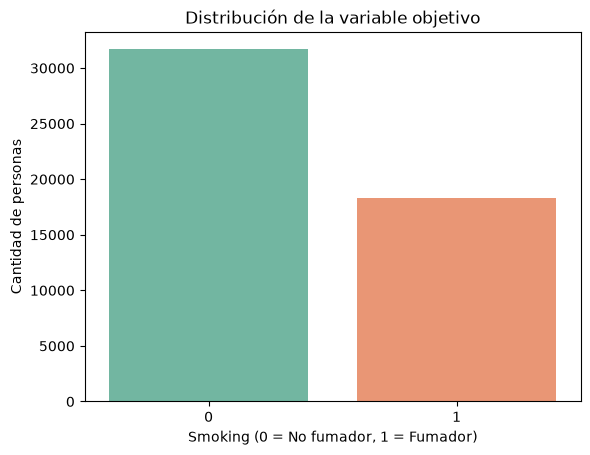

In [24]:

import matplotlib.pyplot as plt
import seaborn as sns

# Distribución de la variable objetivo
conteos = train_clean["smoking"].value_counts().sort_index()
porcentajes = (
    train_clean["smoking"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

display(pd.DataFrame({
    "Cantidad": conteos,
    "Porcentaje (%)": porcentajes.round(2)
}))

ax = sns.countplot(
    data=train_clean,
    x="smoking",
    hue="smoking",
    palette="Set2",
    legend=False
)

ax.set(
    title="Distribución de la variable objetivo",
    xlabel="Smoking (0 = No fumador, 1 = Fumador)",
    ylabel="Cantidad de personas"
)

plt.show()

In [25]:

variables = [
    "age", "height(cm)", "weight(kg)",
    "waist(cm)", "hemoglobin",
    "triglyceride", "HDL", "Gtp"
]

comparacion = train_clean.groupby("smoking")[variables].median().T

comparacion.columns = ["No fumadores", "Fumadores"]

comparacion["Diferencia (%)"] = (
    (comparacion["Fumadores"] - comparacion["No fumadores"])
    / comparacion["No fumadores"] * 100
)

display(
    comparacion.round(2).sort_values(
        "Diferencia (%)",
        key=abs,
        ascending=False
    )
)


,No fumadores,Fumadores,Diferencia (%)
Gtp,21.0,37.0,76.19
triglyceride,96.0,132.0,37.50
weight(kg),60.0,70.0,16.67
age,45.0,40.0,-11.11
HDL,58.0,52.0,-10.34
hemoglobin,14.2,15.5,9.15
height(cm),160.0,170.0,6.25
waist(cm),80.0,84.5,5.62


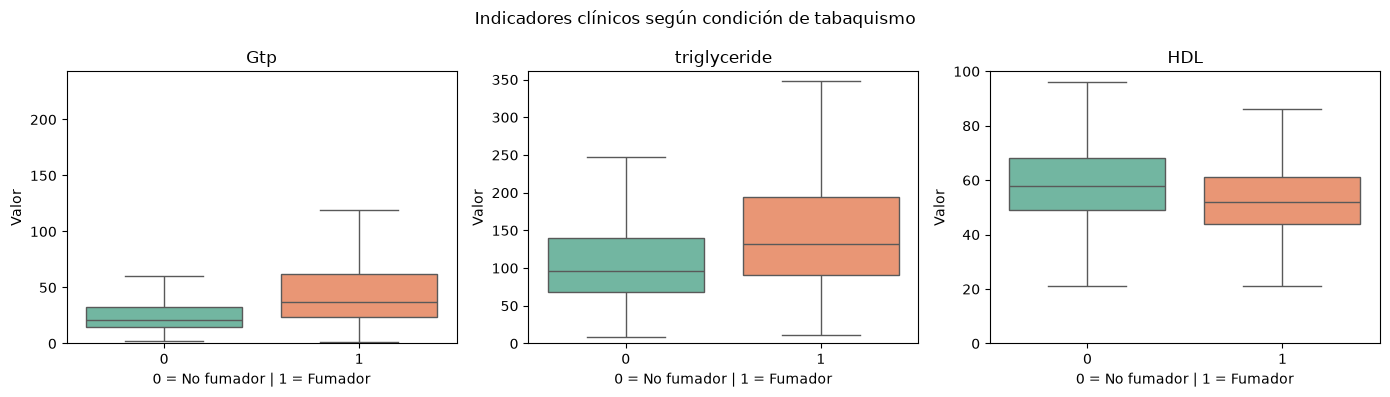

In [26]:

variables_clinicas = ["Gtp", "triglyceride", "HDL"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, variable in zip(axes, variables_clinicas):
    sns.boxplot(
        data=train_clean,
        x="smoking",
        y=variable,
        hue="smoking",
        palette="Set2",
        legend=False,
        showfliers=False,
        ax=ax
    )

    ax.set_ylim(0, train_clean[variable].quantile(0.99))
    ax.set_title(variable)
    ax.set_xlabel("0 = No fumador | 1 = Fumador")
    ax.set_ylabel("Valor")

plt.suptitle("Indicadores clínicos según condición de tabaquismo")
plt.tight_layout()
plt.show()



### Hallazgo exploratorio e implicaciones para el modelado

El análisis identificó diferencias en indicadores bioquímicos según la condición de tabaquismo. Los fumadores presentan medianas superiores de **GTP** (37 frente a 21) y **triglicéridos** (132 frente a 96), mientras que su mediana de **HDL** es inferior (52 frente a 58).

Los diagramas de caja muestran que estas diferencias también se reflejan en las distribuciones, aunque existe una superposición considerable entre ambos grupos. Por lo tanto, estos indicadores podrían aportar información predictiva, pero no permiten establecer relaciones causales.

Dado que también se observaron diferencias demográficas, se plantea la siguiente hipótesis para la etapa de modelado:

**Hipótesis:** incorporar variables clínicas mejora el F1-score de la clase positiva respecto de un modelo basado únicamente en características demográficas.

**Limitación:** las mediciones fueron reconstruidas a partir de un patrón compatible con conversiones horarias de Excel. La reconstrucción es plausible, pero no fue contrastada con una fuente original sin alteraciones.


In [27]:

# Guardar los datasets reconstruidos para el modelado

PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

train_clean.to_csv(
    PROCESSED_DIR / "train_clean.csv",
    index=False
)

predict_clean.to_csv(
    PROCESSED_DIR / "predict_clean.csv",
    index=False
)

# Verificar archivos y estructura
for archivo in ["train_clean.csv", "predict_clean.csv"]:
    ruta = PROCESSED_DIR / archivo
    datos = pd.read_csv(ruta)
    print(f"{archivo}: {datos.shape} | Guardado: {ruta.exists()}")


train_clean.csv: (50000, 27) | Guardado: True
predict_clean.csv: (5692, 26) | Guardado: True



### Conclusiones y preparación para el modelado

La exploración permitió verificar la integridad de ambos datasets: no se identificaron valores faltantes, registros duplicados ni diferencias entre las variables predictoras disponibles.

Se detectaron representaciones numéricas compatibles con conversiones horarias de Excel. A partir del patrón observado, se reconstruyeron las mediciones afectadas y se conservaron los archivos originales para garantizar la trazabilidad del procedimiento.

El análisis exploratorio identificó asociaciones entre el tabaquismo y determinados indicadores bioquímicos, lo que fundamenta la hipótesis que se evaluará durante el entrenamiento.

Los datasets procesados se almacenaron en `data/processed/`. En la siguiente etapa se compararán modelos de clasificación mediante el F1-score de la clase positiva, utilizando una estrategia de validación reproducible.
